## Read scenes

In [32]:
from typing import Union, Literal
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
import drjit as dr
import mitsuba as mi

from util import imshow_compare, imshow_compare_many

mi.set_variant('cuda_ad_rgb', 'llvm_ad_rgb')
print(f"{mi.variant() = }\n")

scene_dict = mi.cornell_box()
cbox_scene = mi.load_dict(scene_dict)
vmis_scene = mi.load_file("./scene/veach-bidir/scene_wo_delta.xml")
vmis_delta_scene = mi.load_file("./scene/veach-bidir/scene.xml")

scene_dict: dict[str, mi.Scene] = {'Cornell box': cbox_scene, 'Veach Bidir /wo Dirac Delta': vmis_scene, 'Veach Bidir w/ Dirac Delta': vmis_delta_scene}

# -------------------- Assertions --------------------
assert isinstance(cbox_scene, mi.Scene)
assert isinstance(vmis_scene, mi.Scene)
assert isinstance(vmis_delta_scene, mi.Scene)

mi.variant() = 'cuda_ad_rgb'



## Render GT

In [33]:
class ImageGT:
    def __init__(self, spp: int):
        assert isinstance(spp, int) and spp > 0
        self.img_dict = dict()
        self.spp = spp
        # self.last_spp = 0
        
        for label in scene_dict.keys():
            self.img_dict[label] = dict()
    
    # def render(self, depth: int, spp: int):
    #     assert isinstance(depth, int) and depth > 0, f"Invalid depth value: {depth = }"
    #     assert isinstance(spp, int) and spp > 0
    #     if spp <= self.last_spp:
    #         print(f"Images with {self.spp = } have already been stored.")
    #     else:
    #         for label, scene in scene_dict.items(): 
    #             self.img_dict[]

    def get(self,
            label: Literal["Cornell box", "Veach MIS", "Veach MIS w/ Dirac Delta"],
            depth: int
           ) -> mi.TensorXf:
        assert label in scene_dict, f"Key error: {label = }"
        assert isinstance(depth, int) and depth > 0, f"Invalid depth value: {depth = }"
        
        if not depth in self.img_dict[label]:
            integ: mi.Integrator = mi.load_dict({'type': 'path', 'max_depth': depth, 'rr_depth': depth})
            self.img_dict[label][depth] = mi.render(scene_dict[label], spp=self.spp,
                                                    integrator=integ)
            
        return self.img_dict[label][depth]
    
# Initialize
spp = 2048
imgGT = ImageGT(spp)

for depth in tqdm([1, 2, 4, 8]):
    for label in scene_dict:
        print(imgGT.get(label, depth).shape)

  0%|          | 0/4 [00:00<?, ?it/s]

(256, 256, 3)
(1024, 1024, 3)


 25%|██▌       | 1/4 [00:04<00:14,  4.85s/it]

(1024, 1024, 3)
(256, 256, 3)
(1024, 1024, 3)


 50%|█████     | 2/4 [00:15<00:16,  8.30s/it]

(1024, 1024, 3)
(256, 256, 3)
(1024, 1024, 3)


 75%|███████▌  | 3/4 [00:33<00:12, 12.59s/it]

(1024, 1024, 3)
(256, 256, 3)
(1024, 1024, 3)


100%|██████████| 4/4 [01:00<00:00, 15.21s/it]

(1024, 1024, 3)


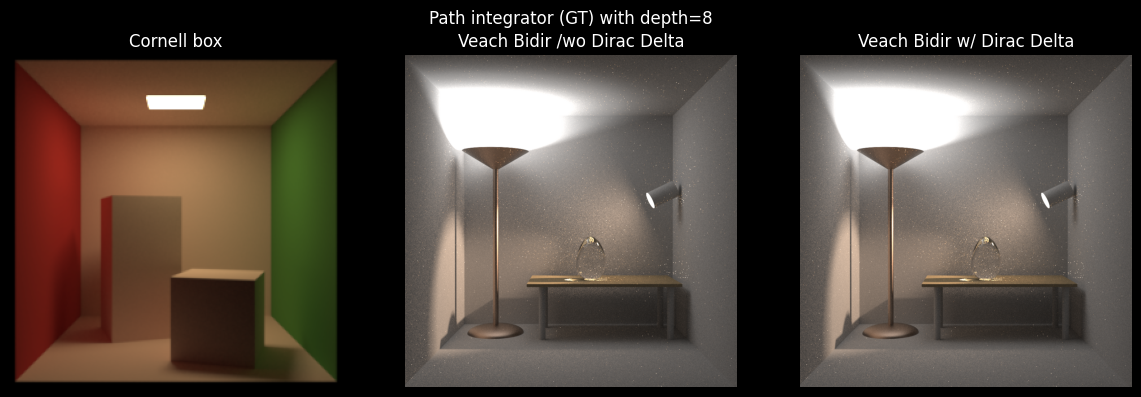

In [34]:
# -------------------- Parameters --------------------
figsize = (12, 4)
if False:
    spp = 256
depth = 8

# -------------------- Visualize --------------------
if False:
    integrator = mi.load_dict({'type': 'path', 'max_depth': depth, 'rr_depth': depth})
    img_gt_dict = dict()

fig, axes = plt.subplots(1, len(scene_dict), figsize=figsize)
# for ax, (label, scene) in zip(axes, scene_dict.items()):
for ax, label in zip(axes, scene_dict.keys()):
    if False:
        img = mi.render(scene, integrator=integrator, spp=spp)
        img_gt_dict[label] = img
    img_gt = imgGT.get(label, depth)
    ax.imshow(mi.Bitmap(dr.clip(img_gt, 0, 1)**(1/2.2)))
    ax.set_title(label)
    ax.set_axis_off()
fig.suptitle(f"Path integrator (GT) with {depth=}")
fig.tight_layout()

## 참고용 메모
If `ctx = mi.BSDFContext(mi.TransportMode.Radiance)` then:

`bsdf.eval(ctx, si, wo)`$= f_s($`wo`$, $`si.wi`$)\left|\hat n \cdot \hat \omega_i\right|$

If `ctx = mi.BSDFContext(mi.TransportMode.Importance)` then:

`bsdf.eval(ctx, si, wo)`$= f_s($`si.wi`$, $`wo`$)\left|\hat n \cdot \hat \omega_i\right|$

Reciprocal BRDF/BSDF = $f_s(\hat\omega_i,\hat\omega_o)=f_s(\hat\omega_o,\hat\omega_i)$

많이 사용되는 diffuse, dielectric, rough dielectric 등은 reciprocal BSDF임

## My BDPT
### Old version archive (commented out)

### Current version: Integrator

### Results

In [9]:
class PathIntegratorFinal(mi.ad.integrators.common.ADIntegrator):
    def __init__(self, props=mi.Properties()):
        super().__init__(props)
        self.max_cameradepth = int(props.get('max_cameradepth', 3))
        self.max_emitterdepth = int(props.get('max_emitterdepth', 3))
        self.light_image_buffer = None
        self.film_size = None
        self.sensor = None
        self.film = None
        self.size = None
        
    def prepare_buffer(self, scene):
        self.sensor: mi.SensorPtr = scene.sensors()[0]
        self.film = self.sensor.film()
        self.size = self.film.crop_size()
        self.film_size = mi.Vector2u(self.size.x, self.size.y)
        self.light_image_buffer = dr.zeros(mi.Float, self.size.x * self.size.y * 3)

    def sample(self,
               mode: dr.ADMode, 
               scene: mi.Scene,
               sampler: mi.Sampler,
               ray: mi.Ray3f,
               active: mi.Bool,
               **kwargs):
        
        ctx_c = mi.BSDFContext(mi.TransportMode.Radiance)
        ctx_e = mi.BSDFContext(mi.TransportMode.Importance) 
        
        L = mi.Spectrum(0.0)
        
        EPW: list[mi.Spectrum] = [mi.Spectrum(0.0) for _ in range(self.max_emitterdepth + 1)]
        EPS: list[mi.SurfaceInteraction3f] = [dr.zeros(mi.SurfaceInteraction3f) for _ in range(self.max_emitterdepth + 1)]
        EPA = [mi.Bool(False) for _ in range(self.max_emitterdepth + 1)]
        EPM = [dr.zeros(mi.Float) for _ in range(self.max_emitterdepth + 1)]
        EP_PDF = [dr.zeros(mi.Float) for _ in range(self.max_emitterdepth + 1)]
        
        emitter_weight = dr.zeros(mi.Spectrum)
        si = dr.zeros(mi.SurfaceInteraction3f)
        
        # ===================================================================
        # Phase 1. Emitter 샘플링 및 초기화
        # ===================================================================
        emitter_idx, emitter_idx_weight, _ = scene.sample_emitter(sampler.next_1d(), active)
        emitter = dr.gather(mi.EmitterPtr, scene.emitters_dr(), emitter_idx)
        
        is_infinite = mi.has_flag(emitter.flags(), mi.EmitterFlags.Infinite)
        is_delta = mi.has_flag(emitter.flags(), mi.EmitterFlags.Delta)
        active_e = active & ~is_infinite & ~is_delta
        
        ps, pos_weight = emitter.sample_position(0.0, sampler.next_2d(), active_e)
        emitter_weight[active_e] = pos_weight * emitter_idx_weight
        
        si.p[active_e] = ps.p
        si.n[active_e] = ps.n
        si.uv[active_e] = ps.uv
        si.time[active_e] = ps.time
        si.sh_frame[active_e] = mi.Frame3f(ps.n)
        
        wo_local = mi.warp.square_to_cosine_hemisphere(sampler.next_2d())
        wavelenghts, wavelenghts_weight = emitter.sample_wavelengths(si, sampler.next_1d(), active_e)
        si.wavelengths = wavelenghts
        
        si.wi[active_e] = wo_local
        wo_world = si.to_world(wo_local)
        
        pdf_emit = ps.pdf / emitter_idx_weight 
        
        EPW[0] = emitter_weight
        EPS[0] = si
        EPA[0] = active_e
        EPM[0] = 0.0
        EP_PDF[0] = pdf_emit
        
        emitter_ray = si.spawn_ray(wo_world)
        
        pdf_dir = mi.warp.square_to_cosine_hemisphere_pdf(wo_local)
        safe_pdf_dir = dr.maximum(1e-6, pdf_dir)
        
        path_weight = emitter_weight * wavelenghts_weight * dr.pi 
        path_weight = dr.select(active_e, path_weight, 0.0)
        
        prev_pdf_fwd = safe_pdf_dir * pdf_emit
        prev_n = si.n
        
        # ===================================================================
        # Phase 2. 광원 서브패스 생성
        # ===================================================================
        for i in range(self.max_emitterdepth):
            si = scene.ray_intersect(emitter_ray)
            active_e = active_e & si.is_valid()
            
            # [수학적 핵심 1] 현재 정점 l_{i+1}이 생성된 전방 면적 확률
            cos_curr = dr.abs(dr.dot(si.n, -emitter_ray.d))
            pdf_fwd_area = dr.select(si.t > 1e-6, prev_pdf_fwd * cos_curr / (si.t * si.t), 0.0)
            
            bsdf_sample, bsdf_weight = si.bsdf().sample(ctx_e, si, sampler.next_1d(), sampler.next_2d(), active_e)
            
            # [수학적 핵심 2] 현재 정점에서 이전 정점 l_i 로 되돌아가는 역방향 확률
            si_rev = si
            si_rev.wi = bsdf_sample.wo
            wo_rev = si.wi
            _, pdf_rev_solid = si.bsdf().eval_pdf(ctx_e, si_rev, wo_rev, active_e)
            
            cos_prev = dr.abs(dr.dot(prev_n, emitter_ray.d))
            pdf_rev_area = dr.select(si.t > 1e-6, pdf_rev_solid * cos_prev / (si.t * si.t), 0.0)
            
            # [MIS 꼬리 누적] R = 역방향 확률 / 이전 정점(l_i)이 생성되었던 전방 확률(EP_PDF[i])
            mis_ratio = dr.select(EP_PDF[i] > 1e-6, pdf_rev_area / EP_PDF[i], 0.0)
            
            idx = i + 1
            EPM[idx] = mis_ratio * (1.0 + EPM[i]) # 꼬리 누적
            EPS[idx] = si
            EPW[idx] = path_weight
            EPA[idx] = active_e
            EP_PDF[idx] = pdf_fwd_area # 다음 정점 계산 및 Phase 4 연결을 위해 보관
            
            path_weight = path_weight * bsdf_weight
            prev_pdf_fwd = bsdf_sample.pdf
            prev_n = si.n
            emitter_ray = si.spawn_ray(si.to_world(bsdf_sample.wo))
        
        return L, active, [], None

In [354]:
import mitsuba as mi 
import drjit as dr

class PathVertex:
    """
    BDPT 경로의 각 정점(Vertex) 정보를 저장하는 데이터 구조.
    DrJit 변수들을 하나로 묶어 관리하여 구조적 안정성을 높입니다.
    """
    def __init__(self):
        self.si = dr.zeros(mi.SurfaceInteraction3f)
        self.weight = mi.Spectrum(0.0)
        self.pdf_fwd = mi.Float(0.0)  # 순방향 Area PDF: p_A(x_{i-1} -> x_i)
        self.pdf_rev = mi.Float(0.0)  # 역방향 Area PDF: p_A(x_i -> x_{i-1})
        self.is_delta = mi.Bool(False) # 거울/유리 등 델타 재질 여부
        self.active = mi.Bool(False)


class PathIntegratorFinal(mi.ad.integrators.common.ADIntegrator):

    def __init__(self, props=mi.Properties()):
        super().__init__(props)
        self.max_camera_depth = int(props.get('max_cameradepth', 3))
        self.max_emitter_depth = int(props.get('max_emitterdepth', 3))
        self.spp = int(props.get('spp', 1))
        self.light_image_buffer = None
        self.film_size = None
        self.sensor = None
        self.film = None
        self.size = None
        


    def prepare_buffer(self, scene):
        self.sensor = scene.sensors()[0]
        self.film = self.sensor.film()
        self.size = self.film.crop_size()
        self.film_size = mi.Vector2u(self.size.x, self.size.y)
        
        if not hasattr(self, 'spp') or self.spp is None:
            self.spp = 1
        
        # Light splatting을 위해 이미지 픽셀 크기만큼의 Float 배열 버퍼 할당 (RGB 3채널)
        self.light_image_buffer = dr.zeros(mi.Float, self.size.x * self.size.y * 3)



    def pdf_solid_angle_to_area(self, pdf_w: mi.Float, p_from: mi.Point3f, p_to: mi.Point3f, n_to: mi.Normal3f):
        """입체각 PDF(Solid Angle PDF)를 면적 PDF(Area PDF)로 변환하는 유틸리티 함수"""
        d_vec = p_from - p_to
        dist_sq = dr.squared_norm(d_vec)
        dist_sq = dr.maximum(dist_sq, 1e-8)  # 0 나누기 방지
        d_dir = d_vec / dr.sqrt(dist_sq)
        cos_theta = dr.abs(dr.dot(n_to, d_dir))
        pdf_area = dr.select(dist_sq > 1e-8, pdf_w * cos_theta / dist_sq, 0.0)
        return pdf_area


    def sample(self, mode: dr.ADMode, scene: mi.Scene, sampler: mi.Sampler,
               ray: mi.Ray3f, active: mi.Bool, **kwargs):

        ctx_c = mi.BSDFContext(mi.TransportMode.Radiance)
        ctx_e = mi.BSDFContext(mi.TransportMode.Importance)

        L = mi.Spectrum(0.0)

        # [Phase 1] 버텍스 배열 초기화

        light_vertices = [PathVertex() for _ in range(self.max_emitter_depth + 1)]
        camera_vertices = [PathVertex() for _ in range(self.max_camera_depth + 1)]

        # ====================================================================
        # [Phase 2] Light Subpath (광원 경로) 추적
        # ====================================================================

        emitter_idx, emitter_idx_weight, _ = scene.sample_emitter(sampler.next_1d(), active)
        emitter = dr.gather(mi.EmitterPtr, scene.emitters_dr(), emitter_idx)


        is_infinite = mi.has_flag(emitter.flags(), mi.EmitterFlags.Infinite)
        is_delta_emitter = mi.has_flag(emitter.flags(), mi.EmitterFlags.Delta)
        active_e = active & ~is_infinite & ~is_delta_emitter

        ps, pos_weight = emitter.sample_position(0.0, sampler.next_2d(), active_e)


        e0_si = dr.zeros(mi.SurfaceInteraction3f)
        e0_si.p, e0_si.n, e0_si.uv, e0_si.time = ps.p, ps.n, ps.uv, ps.time
        e0_si.sh_frame = mi.Frame3f(ps.n)


        #wavelengths, wavelengths_weight = emitter.sample_wavelengths(e0_si, sampler.next_1d(), active_e)
        #e0_si.wavelengths = wavelengths

        wavelengths = ray.wavelengths
        e0_si.wavelengths = wavelengths
        wavelengths_weight = mi.Spectrum(1.0)


        path_weight_e = pos_weight * emitter_idx_weight * wavelengths_weight * dr.pi
        path_weight_e = dr.select(active_e, path_weight_e, 0.0)

        pdf_a_e0 = dr.select(active_e, ps.pdf / dr.maximum(emitter_idx_weight, 1e-8), 0.0)
        weight_y0 = dr.select(active_e, wavelengths_weight / dr.maximum(pdf_a_e0, 1e-8), 0.0)
        y0_weight = dr.select(pdf_a_e0 > 1e-8, wavelengths_weight / pdf_a_e0, 0.0)
        
        light_vertices[0].si = e0_si
        light_vertices[0].weight = dr.select(active_e, y0_weight, 0.0) # Phase 4 연결 시 Le가 곱해지므로 여기선 제외
        light_vertices[0].pdf_fwd = pdf_a_e0
        light_vertices[0].pdf_rev = mi.Float(0.0)
        light_vertices[0].active = active_e
        light_vertices[0].is_delta = mi.Bool(False)

        wo_local_e = mi.warp.square_to_cosine_hemisphere(sampler.next_2d())
        ray_e = e0_si.spawn_ray(e0_si.to_world(wo_local_e))
        prev_si_e = e0_si
        prev_pdf_dir_solid_e = dr.select(active_e, mi.warp.square_to_cosine_hemisphere_pdf(wo_local_e), 0.0)

        e_eval_si = mi.SurfaceInteraction3f(e0_si)
        e_eval_si.wi = wo_local_e
        Le_ray = emitter.eval(e_eval_si, active_e)
        cos_e = mi.Frame3f.cos_theta(wo_local_e)
        #cos_e = wo_local_e.z
        path_weight_e = weight_y0 * dr.select(prev_pdf_dir_solid_e > 0.0, 
                                            (Le_ray * cos_e) / prev_pdf_dir_solid_e, 0.0)

        for i in range(self.max_emitter_depth):
            si_e = scene.ray_intersect(ray_e)
            active_e &= si_e.is_valid()

            pdf_fwd_area = self.pdf_solid_angle_to_area(prev_pdf_dir_solid_e, prev_si_e.p, si_e.p, si_e.n)

            idx = i + 1
            light_vertices[idx].si = si_e
            light_vertices[idx].weight = path_weight_e
            light_vertices[idx].pdf_fwd = pdf_fwd_area
            light_vertices[idx].active = active_e

            bsdf_sample, bsdf_weight = si_e.bsdf().sample(ctx_e, si_e, sampler.next_1d(), sampler.next_2d(), active_e)
            
            si_rev_e = mi.SurfaceInteraction3f(si_e)
            si_rev_e.wi = bsdf_sample.wo # 방금 쏠 방향에서 역으로 빛이 들어왔다고 가정
            _, pdf_rev_solid = si_e.bsdf().eval_pdf(ctx_e, si_rev_e, si_e.wi, active_e) # 이전 위치로 반사될 확률
            pdf_rev_area = self.pdf_solid_angle_to_area(pdf_rev_solid, si_e.p, prev_si_e.p, prev_si_e.n)
            light_vertices[idx].pdf_rev = pdf_rev_area
            
            path_weight_e *= bsdf_weight
            light_vertices[idx].is_delta = mi.has_flag(bsdf_sample.sampled_type, mi.BSDFFlags.Delta)

            prev_si_e = si_e
            prev_pdf_dir_solid_e = bsdf_sample.pdf
            ray_e = si_e.spawn_ray(si_e.to_world(bsdf_sample.wo))

        # ====================================================================
        # [Phase 3] Camera Subpath (카메라 경로) 추적
        # ====================================================================

        beta_c = mi.Spectrum(1.0)
        ray_c = mi.Ray3f(ray)
        active_c = mi.Bool(active)

        prev_si_c = dr.zeros(mi.SurfaceInteraction3f)
        prev_pdf_dir_solid_c = mi.Float(1.0)

        for i in range(self.max_camera_depth):
            si_c = scene.ray_intersect(ray_c)
            si_c.wavelengths = ray.wavelengths
            active_c &= si_c.is_valid()

            is_delta_c = mi.has_flag(si_c.bsdf().flags(), mi.BSDFFlags.Delta)


            if i > 0:
                pdf_fwd_area = self.pdf_solid_angle_to_area(prev_pdf_dir_solid_c, prev_si_c.p, si_c.p, si_c.n)
            else:
                pdf_fwd_area = mi.Float(1.0)


            camera_vertices[i].si = si_c
            camera_vertices[i].weight = beta_c
            camera_vertices[i].pdf_fwd = pdf_fwd_area
            camera_vertices[i].active = active_c
            camera_vertices[i].is_delta = is_delta_c

            bsdf_sample_c, bsdf_weight_c = si_c.bsdf().sample(ctx_c, si_c, sampler.next_1d(), sampler.next_2d(), active_c)
            
            if i > 0:
                si_rev_c = mi.SurfaceInteraction3f(si_c)
                si_rev_c.wi = bsdf_sample_c.wo
                _, pdf_rev_solid = si_c.bsdf().eval_pdf(ctx_c, si_rev_c, si_c.wi, active_c)
                pdf_rev_area = self.pdf_solid_angle_to_area(pdf_rev_solid, si_c.p, prev_si_c.p, prev_si_c.n)
                camera_vertices[i].pdf_rev = pdf_rev_area
            else:
                camera_vertices[i].pdf_rev = mi.Float(1.0)
            
            beta_c *= bsdf_weight_c
            prev_si_c = si_c
            prev_pdf_dir_solid_c = bsdf_sample_c.pdf
            ray_c = si_c.spawn_ray(si_c.to_world(bsdf_sample_c.wo))
            
            emitter_hit = si_c.emitter(scene)
            active_e_hit = active_c & (emitter_hit != None)
            if i > 0:
                L += dr.select(active_e_hit & is_delta_c, beta_c * emitter_hit.eval(si_c, active_e_hit), 0.0)
            
            
            

        c0_si = camera_vertices[0].si
        emitter_direct = c0_si.emitter(scene) 
        active_direct_hit = camera_vertices[0].active & (emitter_direct != None)
        Le_direct = emitter_direct.eval(c0_si, active_direct_hit)
        L += dr.select(active_direct_hit, Le_direct, 0.0)

        # ====================================================================
        # [Phase 4 & 5] Vertex Connection 및 MIS Weight Assembly
        # ====================================================================

        for i in range(self.max_camera_depth):
            v_c = camera_vertices[i]

            for j in range(self.max_emitter_depth + 1):
                
                v_e = light_vertices[j]
                active_conn = v_c.active & v_e.active & ~v_c.is_delta & ~v_e.is_delta

                d_vec = v_e.si.p - v_c.si.p
                dist_sq = dr.maximum(dr.squared_norm(d_vec), 1e-8)
                dist = dr.sqrt(dist_sq)

                wo_c = d_vec / dist
                wo_e = -wo_c

                wo_c_local = v_c.si.to_local(wo_c)
                wo_e_local = v_e.si.to_local(wo_e)

                shadow_ray = v_c.si.spawn_ray_to(v_e.si.p)
                visible = active_conn & ~scene.ray_test(shadow_ray)

                f_c = v_c.si.bsdf().eval(ctx_c, v_c.si, wo_c_local, visible)
                f_e = mi.Spectrum(0.0)
                G_term = mi.Float(0.0)

                if j == 0:
                    cos_e_dot = dr.dot(v_e.si.n, wo_e)
                    valid_emission = visible & (cos_e_dot > 0.0)

                    v_e_si_eval = mi.SurfaceInteraction3f(v_e.si)
                    v_e_si_eval.wi = wo_e_local

                    Le = emitter.eval(v_e_si_eval, valid_emission)
                    f_e = Le
                    G_term = dr.select(dist_sq > 1e-8, cos_e_dot / dist_sq, 0.0)
                    visible = valid_emission
                else:
                    f_e = v_e.si.bsdf().eval(ctx_e, v_e.si, wo_e_local, visible)
                    G_term = dr.select(dist_sq > 1e-8, 1.0 / dist_sq, 0.0)


                L_unweighted = v_c.weight * f_c * G_term * f_e * v_e.weight
                L_unweighted = dr.clip(L_unweighted, 0.0, 1000.0)


                # --- MIS 가중치 조립 (Area PDF 기반 연쇄 분수 계산) ---
                if j == 0:
                    pdf_w_e = mi.warp.square_to_cosine_hemisphere_pdf(wo_e_local)
                else:
                    _, pdf_w_e = v_e.si.bsdf().eval_pdf(ctx_e, v_e.si, wo_e_local, visible)


                pdf_A_light_to_cam = self.pdf_solid_angle_to_area(pdf_w_e, v_e.si.p, v_c.si.p, v_c.si.n)

                _, pdf_w_c = v_c.si.bsdf().eval_pdf(ctx_c, v_c.si, wo_c_local, visible)
                pdf_A_cam_to_light = self.pdf_solid_angle_to_area(pdf_w_c, v_c.si.p, v_e.si.p, v_e.si.n)

                mis_sum = mi.Float(1.0)
                
                prev_i = i - 1 if i > 0 else 0
                
                # 카메라 연결점(i)의 역방향 PDF
                si_rev_c_conn = mi.SurfaceInteraction3f(v_c.si)
                si_rev_c_conn.wi = wo_c_local 
                _, pdf_rev_solid_conn_c = v_c.si.bsdf().eval_pdf(ctx_c, si_rev_c_conn, v_c.si.wi, visible)
                pdf_rev_area_conn_c = dr.select(i > 0, self.pdf_solid_angle_to_area(pdf_rev_solid_conn_c, v_c.si.p, camera_vertices[prev_i].si.p, camera_vertices[prev_i].si.n), 1.0)
                
                prev_j = j - 1 if j > 0 else 0
                
                # 광원 연결점(j)의 역방향 PDF
                si_rev_e_conn = mi.SurfaceInteraction3f(v_e.si)
                si_rev_e_conn.wi = wo_e_local 
                _, pdf_rev_solid_conn_e = v_e.si.bsdf().eval_pdf(ctx_e, si_rev_e_conn, v_e.si.wi, visible)
                pdf_rev_area_conn_e = dr.select(j > 0, self.pdf_solid_angle_to_area(pdf_rev_solid_conn_e, v_e.si.p, light_vertices[prev_j].si.p, light_vertices[prev_j].si.n), 0.0)


                # 1) 카메라 방향으로 비율 합산
                ratio_cam = dr.select(v_c.pdf_fwd > 1e-8, pdf_A_light_to_cam / v_c.pdf_fwd, 0.0)
                rem_ratio = dr.select(i > 0, ratio_cam, 0.0)
                is_delta_curr = mi.Bool(v_c.is_delta)

                for k in range(i, 0, -1):
                    mis_sum += dr.select(~is_delta_curr, rem_ratio, 0.0)
                    prev_fwd = camera_vertices[k-1].pdf_fwd
                    curr_rev = pdf_rev_area_conn_c if k == i else camera_vertices[k].pdf_rev
                    step_ratio = dr.select(prev_fwd > 1e-8, curr_rev / prev_fwd, 0.0)
                    rem_ratio *= step_ratio
                    is_delta_curr = camera_vertices[k-1].is_delta

                mis_sum += dr.select(~is_delta_curr, rem_ratio, 0.0)

                # 2) 광원 방향으로 비율 합산
                ratio_light = dr.select(v_e.pdf_fwd > 1e-8, pdf_A_cam_to_light / v_e.pdf_fwd, 0.0)
                rem_ratio_light = dr.select((j == 0) & (i > 0) & ~v_c.is_delta, 0.0, ratio_light)
                is_delta_curr_e = mi.Bool(v_e.is_delta)

                for k in range(j, 0, -1):
                    mis_sum += dr.select(~is_delta_curr_e, rem_ratio_light, 0.0)
                    prev_fwd = light_vertices[k-1].pdf_fwd
                    curr_rev = pdf_rev_area_conn_e if k == j else light_vertices[k].pdf_rev
                    step_ratio = dr.select(prev_fwd > 1e-8, curr_rev / prev_fwd, 0.0)
                    rem_ratio_light *= step_ratio
                    is_delta_curr_e = light_vertices[k-1].is_delta
                mis_sum += dr.select(~is_delta_curr_e, rem_ratio_light, 0.0)


                # 3) 최종 결합
                mis_weight = dr.select(visible & (mis_sum > 0.0), 1.0 / mis_sum, 0.0)
                mis_weight = dr.select(dr.isfinite(mis_weight), mis_weight, 0.0)
                L += dr.select(visible, L_unweighted * mis_weight, 0.0)

        # ====================================================================
        # [Phase 6] Light Splatting (t=1 전략: 광원 -> 렌즈 직접 투사)
        # ====================================================================

        for j in range(1, self.max_emitter_depth + 1):
            if j == 0:
                continue
            
            v_e = light_vertices[j]

            ds, sensor_val = self.sensor.sample_direction(v_e.si, sampler.next_2d(), v_e.active)
            active_splat = v_e.active & (ds.pdf > 0.0) & ~v_e.is_delta

            shadow_ray = v_e.si.spawn_ray_to(ds.p)
            visible_splat = active_splat & ~scene.ray_test(shadow_ray)

            d_vec = ds.p - v_e.si.p
            dist_sq = dr.maximum(ds.dist * ds.dist, 1e-8)
            dist = dr.sqrt(dist_sq)

            wo_e_splat = d_vec / dist
            wo_e_local_splat = v_e.si.to_local(wo_e_splat)

            f_e_splat = mi.Spectrum(0.0)
            if j == 0:
                cos_e_dot = dr.dot(v_e.si.n, wo_e_splat)
                valid_emission = visible_splat & (cos_e_dot > 0.0)
                v_e_si_eval = mi.SurfaceInteraction3f(v_e.si)
                v_e_si_eval.wi = wo_e_local_splat
                f_e_splat = emitter.eval(v_e_si_eval, valid_emission)
                visible_splat = valid_emission
            else:
                f_e_splat = v_e.si.bsdf().eval(ctx_e, v_e.si, wo_e_local_splat, visible_splat)

            spp_f = mi.Float(self.spp)
            L_splat_unweighted = (v_e.weight * f_e_splat * sensor_val) / spp_f
            L_splat_unweighted = dr.clip(L_splat_unweighted, 0.0, 1000.0)

            # Splatting용 역방향 MIS 계산
            pdf_A_cam_to_e = ds.pdf
            
            if j == 0:
                pdf_w_e_splat = mi.warp.square_to_cosine_hemisphere_pdf(wo_e_local_splat)
            else:
                _, pdf_w_e_splat = v_e.si.bsdf().eval_pdf(ctx_e, v_e.si, wo_e_local_splat, visible_splat)
            
            pdf_A_e_to_cam = self.pdf_solid_angle_to_area(pdf_w_e_splat, v_e.si.p, ds.p, ds.n)
            
            si_rev_e_splat = mi.SurfaceInteraction3f(v_e.si)
            si_rev_e_splat.wi = wo_e_local_splat  # 렌즈 방향에서 빛이 거꾸로 들어왔다고 가정
            _, pdf_rev_solid_splat = v_e.si.bsdf().eval_pdf(ctx_e, si_rev_e_splat, v_e.si.wi, visible_splat)
            prev_j = j - 1 if j > 0 else 0
            pdf_rev_area_conn_e_splat = self.pdf_solid_angle_to_area(pdf_rev_solid_splat, v_e.si.p, light_vertices[prev_j].si.p, light_vertices[prev_j].si.n)

            mis_sum_splat = mi.Float(1.0)
            ratio_light_splat = dr.select(v_e.pdf_fwd > 1e-8, pdf_A_cam_to_e / v_e.pdf_fwd, 0.0)
            rem_ratio_splat = mi.Float(ratio_light_splat)
            is_delta_curr_splat = mi.Bool(v_e.is_delta)

            for k in range(j, 0, -1):
                mis_sum_splat += dr.select(~is_delta_curr_splat, rem_ratio_splat, 0.0)
                prev_fwd = light_vertices[k-1].pdf_fwd
                curr_rev = pdf_rev_area_conn_e_splat if k == j else light_vertices[k].pdf_rev
                step_ratio = dr.select(prev_fwd > 1e-8, curr_rev / prev_fwd, 0.0)
                rem_ratio_splat *= step_ratio
                is_delta_curr_splat = light_vertices[k-1].is_delta


            mis_sum_splat += dr.select(~is_delta_curr_splat, rem_ratio_splat, 0.0)

            mis_weight_splat = dr.select(visible_splat & (mis_sum_splat > 0.0), 1.0 / mis_sum_splat, 0.0)
            mis_weight_splat = dr.select(dr.isfinite(mis_weight_splat), mis_weight_splat, 0.0)
            L_splat = dr.select(visible_splat, L_splat_unweighted * mis_weight_splat, 0.0)


            # 버퍼에 RGB 누적
            width_f = mi.Float(self.film_size.x)
            height_f = mi.Float(self.film_size.y)
            pos_x = dr.clip(dr.floor(ds.uv.x), 0.0, width_f - 1.0)
            pos_y = dr.clip(dr.floor(ds.uv.y), 0.0, height_f - 1.0)

            pixel_idx = (mi.UInt32(pos_y) * self.film_size.x + mi.UInt32(pos_x)) * 3

            dr.scatter_add(target=self.light_image_buffer, value=L_splat[0], index=pixel_idx + 0, active=visible_splat)
            dr.scatter_add(target=self.light_image_buffer, value=L_splat[1], index=pixel_idx + 1, active=visible_splat)
            dr.scatter_add(target=self.light_image_buffer, value=L_splat[2], index=pixel_idx + 2, active=visible_splat)


        return L, active, [], None

In [358]:
mi.register_integrator("mypath", lambda props: PathIntegratorFinal(props))

spp = 1024
depth_sensor = 2
depth_emitter = 0

import os

props = mi.Properties()
props['max_cameradepth'] = depth_sensor
props['max_emitterdepth'] = depth_emitter

mypath = PathIntegratorFinal(props)



In [359]:
img_ours_dict = {}
for label, scene in scene_dict.items():
    mypath.prepare_buffer(scene)
    
    # 1. 메인 카메라 경로 이미지 렌더링
    img = mi.render(scene, integrator=mypath, spp=spp)
    
    dr.eval(mypath.light_image_buffer)
    
    sensor = mypath.sensor
    film_size = sensor.film().crop_size()
    light_buffer_flat = mypath.light_image_buffer
    
    img_light = mi.TensorXf(light_buffer_flat, shape=(film_size.y, film_size.x, 3))
    
    img_rgb = img[:, :, :3]
    
    final_img = img_rgb + (img_light / spp)
    
    img_ours_dict[label] = final_img

In [ ]:
for label in scene_dict:
    depth_total = depth_sensor + depth_emitter + 1
    title = f"{label} D{depth_total}"
    imshow_compare(img_ours_dict[label].numpy(), imgGT.get(label, depth_total).numpy(),
                   figsize=(90, 27), suptitle=title, vabs=1.0)